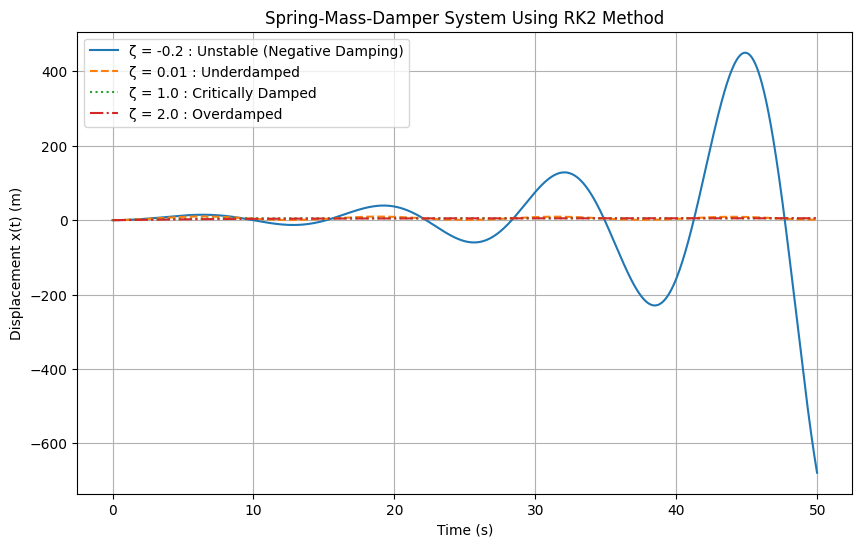

In [3]:
import numpy as np
import matplotlib.pyplot as plt

F = 5
w = 0.5
t0 = 0
T = 50
dt = 0.01
N = int((T - t0) / dt)
t = np.arange(N) * dt

def du(u, z):
    return np.array([
        u[1],
        w**2 * (F - u[0]) - 2 * z * w * u[1]
    ])


# Damping ratio, condition, and line style
damping_cases = [
    (-0.2, "Unstable (Negative Damping)", "-"),
    (0.01, "Underdamped", "--"),
    (1.0, "Critically Damped", ":"),
    (2.0, "Overdamped", "-.")
]


u = np.zeros((N, 2))

plt.figure(figsize=(10, 6))


for z, condition, style in damping_cases:

    # Initial conditions
    u[:, :] = 0
    u[0] = [0, 0]

    for i in range(N - 1):

        # RK2 first slope
        k1 = du(u[i], z)

        # Midpoint
        u_mid = u[i] + (dt / 2) * k1

        # RK2 second slope
        k2 = du(u_mid, z)

        # RK2 update
        u[i + 1] = u[i] + dt * k2

    # Plot using different line styles
    plt.plot(
        t,
        u[:, 0],
        linestyle=style,
        linewidth=1.5,
        label=f"ζ = {z} : {condition}"
    )


plt.xlabel("Time (s)")
plt.ylabel("Displacement x(t) (m)")
plt.title("Spring-Mass-Damper System Using RK2 Method")
plt.grid(True)
plt.legend()
plt.show()